<a href="https://colab.research.google.com/github/alberttrier/uk-house-price-forecasting/blob/main/uk_house_prices.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [4]:
print("hello")

hello


Index(['Date', 'RegionName', 'AreaCode', 'AveragePrice', 'Index', 'IndexSA',
       '1m%Change', '12m%Change', 'AveragePriceSA', 'SalesVolume',
       'DetachedPrice', 'DetachedIndex', 'Detached1m%Change',
       'Detached12m%Change', 'SemiDetachedPrice', 'SemiDetachedIndex',
       'SemiDetached1m%Change', 'SemiDetached12m%Change', 'TerracedPrice',
       'TerracedIndex', 'Terraced1m%Change', 'Terraced12m%Change', 'FlatPrice',
       'FlatIndex', 'Flat1m%Change', 'Flat12m%Change', 'CashPrice',
       'CashIndex', 'Cash1m%Change', 'Cash12m%Change', 'CashSalesVolume',
       'MortgagePrice', 'MortgageIndex', 'Mortgage1m%Change',
       'Mortgage12m%Change', 'MortgageSalesVolume', 'FTBPrice', 'FTBIndex',
       'FTB1m%Change', 'FTB12m%Change', 'FOOPrice', 'FOOIndex', 'FOO1m%Change',
       'FOO12m%Change', 'NewPrice', 'NewIndex', 'New1m%Change',
       'New12m%Change', 'NewSalesVolume', 'OldPrice', 'OldIndex',
       'Old1m%Change', 'Old12m%Change', 'OldSalesVolume'],
      dtype='object

<Axes: xlabel='Date'>

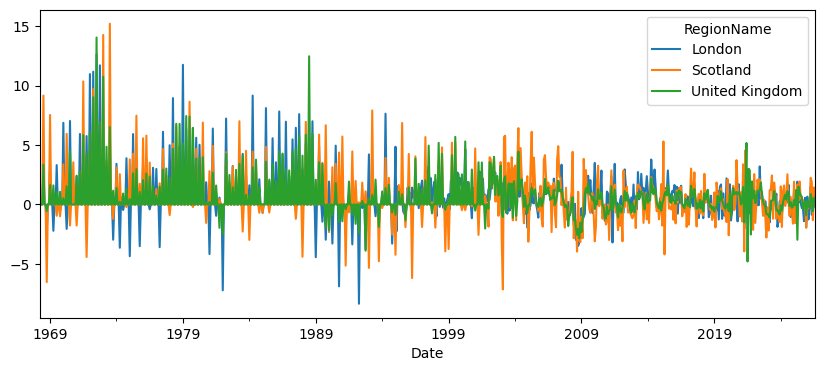

In [5]:
import pandas as pd
import numpy as np

df = pd.read_csv("/content/UK-HPI-full-file-2026-08.csv")
print(df.columns)
print(df.head())

df["Date"] = pd.to_datetime(df["Date"], dayfirst=True)
regions = ["London", "Scotland", "United Kingdom"]
df = df[df["RegionName"].isin(regions)]

prices = df.pivot(index="Date", columns="RegionName", values="AveragePrice")
growth = np.log(prices).diff() * 100
growth.plot(figsize=(10, 4))

RegionName
London           2005-01-01
Scotland         2005-01-01
United Kingdom   2005-01-01
dtype: datetime64[ns]
RegionName
London            0
Scotland          0
United Kingdom    0
dtype: int64


<Axes: xlabel='Date'>

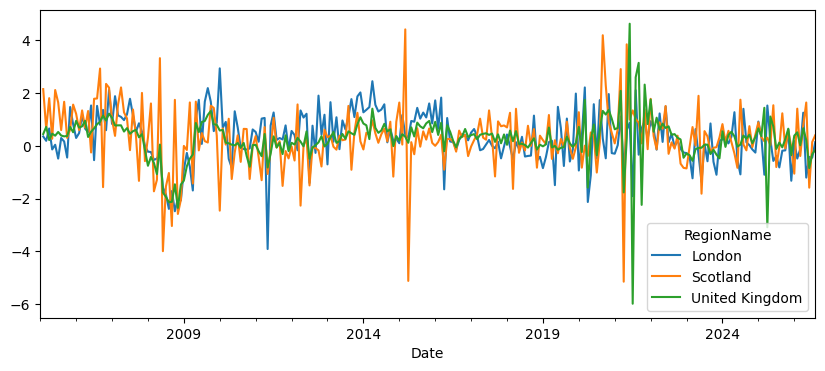

In [6]:
prices = df.pivot(index="Date", columns="RegionName", values="AveragePriceSA")
prices = prices.loc["2005-01-01":]

print(prices.apply(lambda s: s.first_valid_index()))
print(prices.isna().sum())

growth = np.log(prices).diff() * 100
growth.plot(figsize=(10, 4))

Lag-1 autocorrelation:
RegionName
London            0.217202
Scotland         -0.183726
United Kingdom    0.014416
dtype: float64


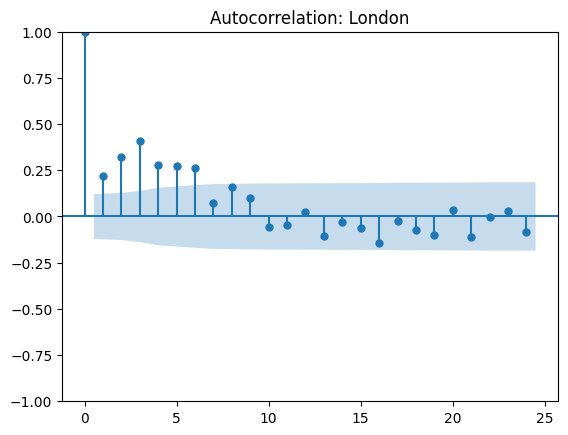

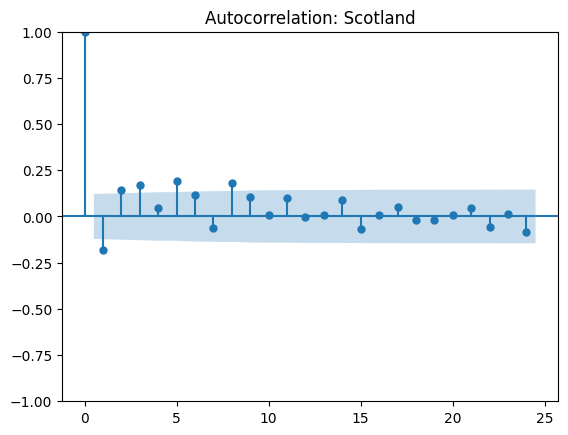

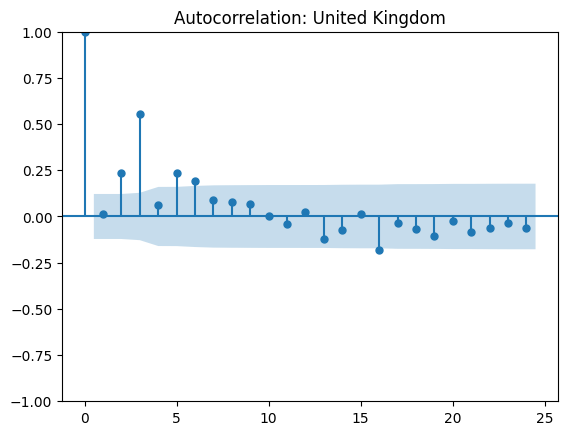

In [7]:
from statsmodels.graphics.tsaplots import plot_acf
import matplotlib.pyplot as plt

growth = growth.dropna()

print("Lag-1 autocorrelation:")
print(growth.apply(lambda s: s.autocorr(lag=1)))

for region in growth.columns:
  plot_acf(growth[region], lags=24, title=f"Autocorrelation: {region}")
  plt.show()


Observed lag-3: 0.5582483833330866
Share of shuffles at least this strong: 0.0


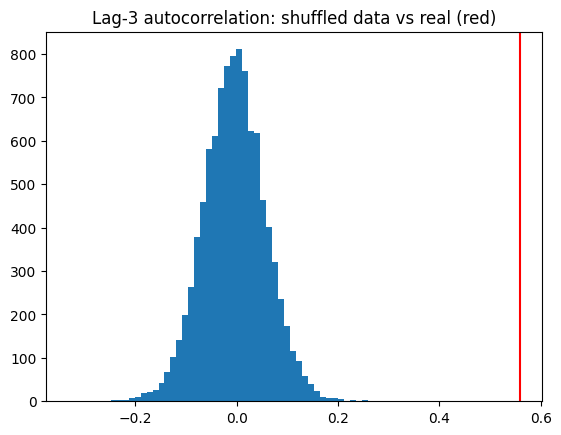

In [8]:
rng = np.random.default_rng(42)
s = growth["United Kingdom"]
observed = s.autocorr(lag=3)

fake = [pd.Series(rng.permutation(s.values)).autocorr(lag=3) for _ in range(10000)]
p_value = np.mean(np.abs(fake) >= abs(observed))

print("Observed lag-3:", observed)
print("Share of shuffles at least this strong:", p_value)

plt.hist(fake, bins=50)
plt.axvline(observed, color="red")
plt.title("Lag-3 autocorrelation: shuffled data vs real (red)")
plt.show()

In [9]:
from statsmodels.stats.diagnostic import acorr_ljungbox

for region in growth.columns:
  print(region)
  print(acorr_ljungbox(growth[region], lags=[3, 6, 12]))

London
       lb_stat     lb_pvalue
3    83.595053  5.196372e-18
6   142.731445  2.656925e-28
12  155.651741  4.032118e-27
Scotland
      lb_stat     lb_pvalue
3   21.645785  7.729167e-05
6   35.496887  3.452098e-06
12  50.892170  9.731964e-07
United Kingdom
       lb_stat     lb_pvalue
3    95.739552  1.280482e-20
6   121.158309  9.305923e-24
12  126.650200  2.897755e-21


In [10]:
def vol_aware_shuffle(series, n_groups, rng):

  vol = series.rolling(12, center=True, min_periods=6).std()
  groups = pd.qcut(vol, q=n_groups, labels=False)
  shuffled = series.copy()
  for g in range (n_groups):
    months = groups.index[groups == g]
    shuffled.loc[months] = rng.permutation(series.loc[months].values)
  return shuffled

for region in growth.columns:
  s = growth[region]
  observed = s.autocorr(lag=3)
  rng = np.random.default_rng(42)

  plain = [pd.Series(rng.permutation(s.values)).autocorr(lag=3) for _ in range(10000)]
  print(region, "| real lag-3:", round(observed, 3),
  "| plain shuffle p:", np.mean(np.abs(plain) >= abs(observed)))


  for n_groups in [2, 3, 4]:
    fake = [vol_aware_shuffle(s, n_groups, rng).autocorr(lag=3) for _ in range(10000)]
    print("  ", n_groups, "groups -> p:", np.mean(np.abs(fake) >= abs(observed)))




London | real lag-3: 0.408 | plain shuffle p: 0.0
   2 groups -> p: 0.0
   3 groups -> p: 0.0
   4 groups -> p: 0.0
Scotland | real lag-3: 0.171 | plain shuffle p: 0.0052
   2 groups -> p: 0.0152
   3 groups -> p: 0.0238
   4 groups -> p: 0.0321
United Kingdom | real lag-3: 0.558 | plain shuffle p: 0.0
   2 groups -> p: 0.0
   3 groups -> p: 0.0
   4 groups -> p: 0.0
